# Spatial analysis of the 2026 Alberta referendum, question 10
Joseph and Zarif. Adapted from a collaborator's Colab notebook; the script version is `scripts/06-spatial_analysis.py`.

**Boundaries** are the 2017 electoral division polygons from the Government of Alberta (`data/01-raw_data/ab_electoral_divisions_2017.geojson`, simplified), the divisions in force in 2026. **Region labels** in `ed_regions.csv` were carried over from the collaborator notebook and not independently verified. There is no regression: the original notebook's covariates were randomly generated and were removed. Votes come from `data/02-analysis_data/ed_results_2026.csv`.

Run from the project root's `notebooks/` folder with the project virtual environment.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec

from common import ANALYSIS, EXPECTED_2026, RAW

K_NEIGHBOURS = 5
N_PERMUTATIONS = 9999
SEED = 42
REGION_COLOURS = {"Edmonton": "#4575b4", "Calgary": "#74add1", "Central": "#fdae61",
                  "North": "#f46d43", "South": "#d73027"}
LISA_COLOURS = {"High-High": "#d73027", "Low-Low": "#4575b4",
                "High-Low": "#fdae61", "Low-High": "#abd9e9"}

## 1. Load question 10 and riding locations
Option 2 is the second choice on the ballot. The assertions tie the data to the published provincial totals.

In [2]:
results = pd.read_csv(ANALYSIS / "ed_results_2026.csv", dtype={"ed_code": str})
q10 = results[results["question_number"] == 10].copy()
q10["total"] = q10["choice_1_votes"] + q10["choice_2_votes"]
q10["option2_pct"] = 100 * q10["choice_2_votes"] / q10["total"]

regions = pd.read_csv(RAW / "ed_regions.csv", dtype={"ed_code": str})[["ed_code", "region"]]
shapes = gpd.read_file(RAW / "ab_electoral_divisions_2017.geojson")
shapes["ed_code"] = shapes["EDNUMBER"].astype(int).map("{:02d}".format)

gdf = (shapes[["ed_code", "geometry"]].merge(q10, on="ed_code", how="right")
       .merge(regions, on="ed_code", how="left"))
gdf = gpd.GeoDataFrame(gdf, geometry="geometry", crs=shapes.crs)

assert len(gdf) == 87 and gdf.geometry.notna().all() and gdf["region"].notna().all()
assert gdf["choice_1_votes"].sum() == EXPECTED_2026[10]["choice_1"]
assert gdf["choice_2_votes"].sum() == EXPECTED_2026[10]["choice_2"]

# Centroids in a metric projection (NAD83 / Alberta 10-TM Forest); lon/lat for plotting
metric = gdf.to_crs(3400)
gdf["x"], gdf["y"] = metric.centroid.x, metric.centroid.y
cent = metric.centroid.to_crs(4326)
gdf["lon"], gdf["lat"] = cent.x, cent.y
df = pd.DataFrame(gdf.drop(columns="geometry"))

y = df["option2_pct"].to_numpy()
print(f"Option 2 share, provincial: {100 * df['choice_2_votes'].sum() / df['total'].sum():.2f}%")
print(f"Divisions above 50%: {(y > 50).sum()}")
df.loc[y > 50, ["ed_name", "option2_pct"]]

Option 2 share, provincial: 25.05%
Divisions above 50%: 2


,ed_name,option2_pct
54,CENTRAL PEACE-NOTLEY,50.459921
79,RIMBEY-ROCKY MOUNTAIN HOUSE-SUNDRE,50.937487


## 2. Choropleth with Calgary and Edmonton insets

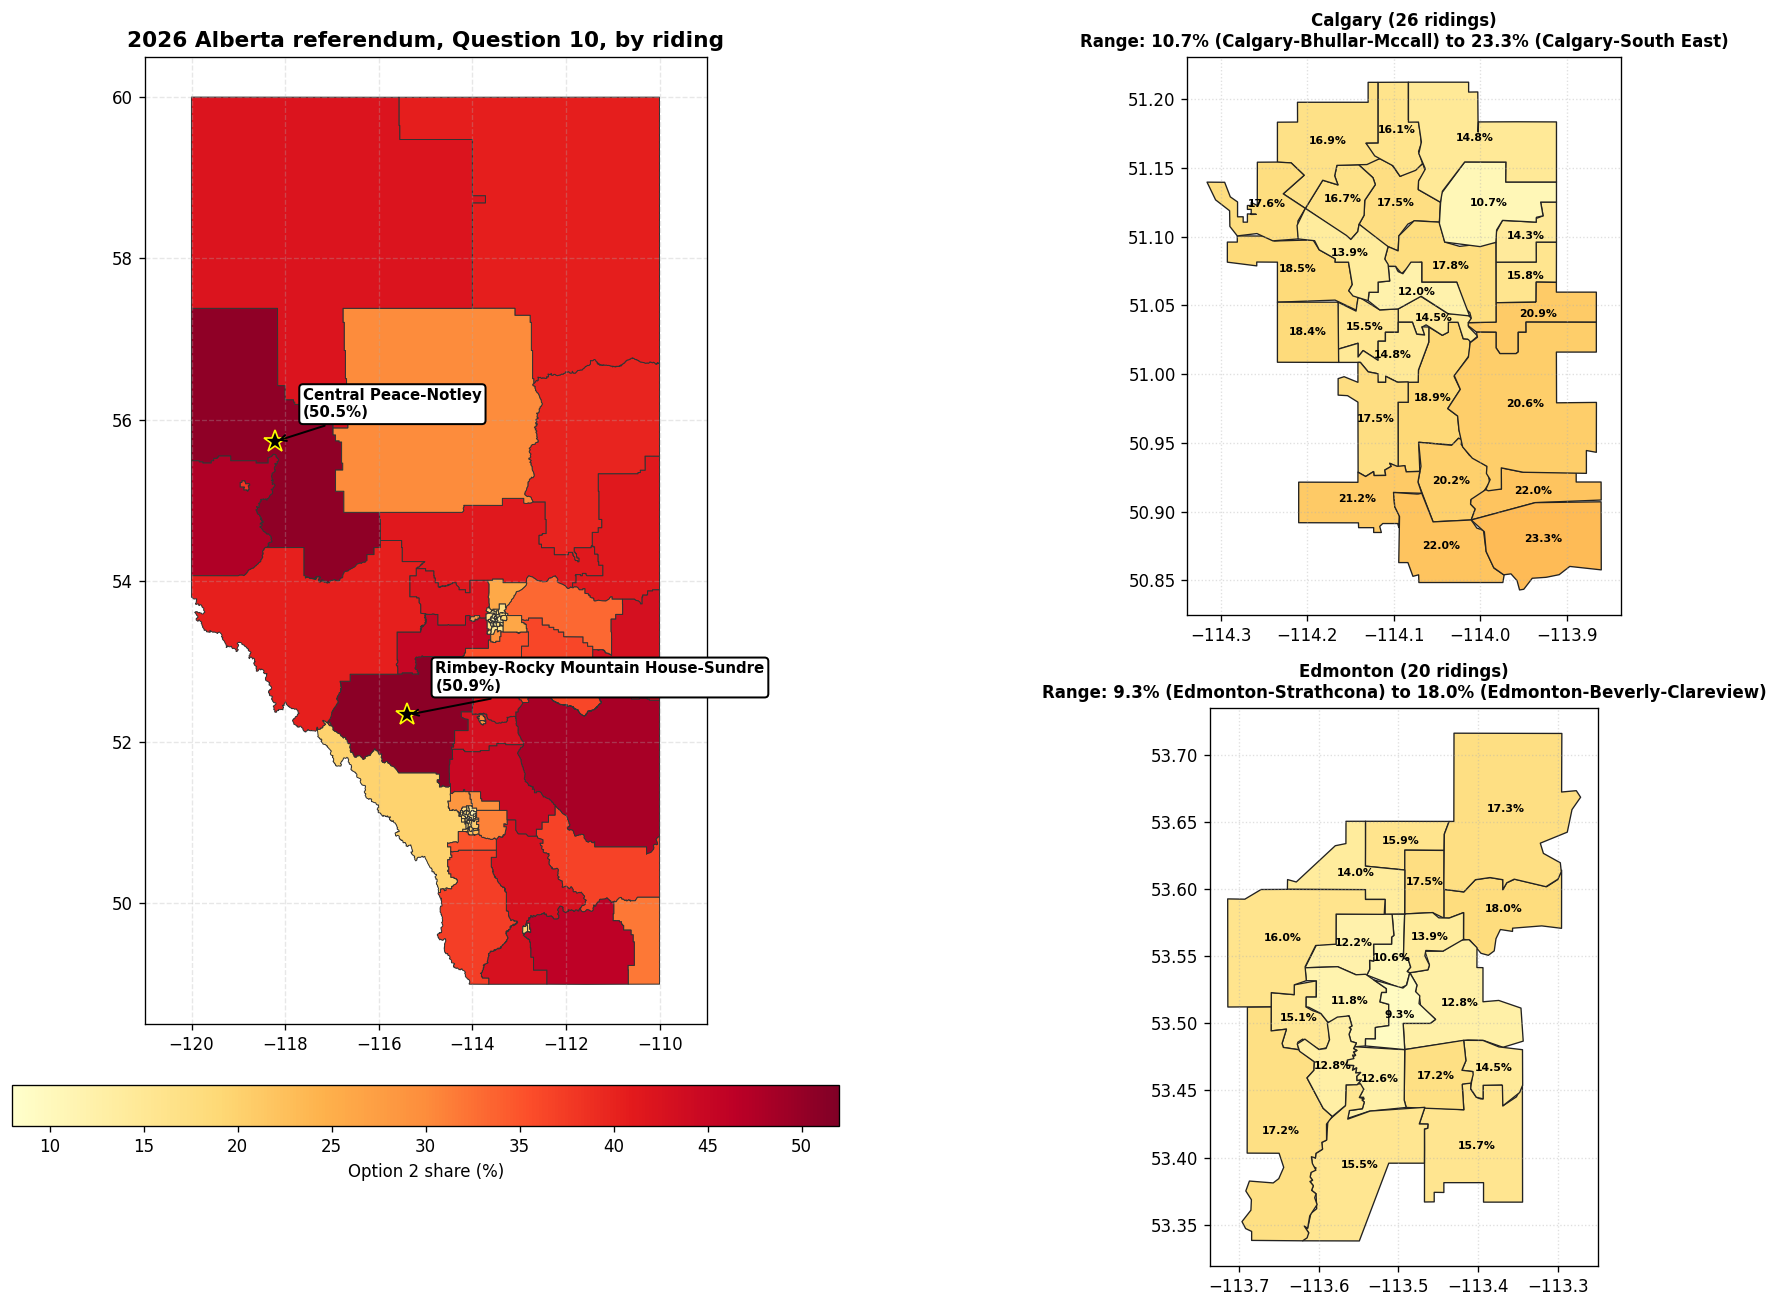

In [3]:
VMIN, VMAX = 8.0, 52.0
LABEL = "Option 2 share (%)"

fig = plt.figure(figsize=(18, 11), dpi=120)
gs = GridSpec(2, 2, width_ratios=[1.25, 1.0], height_ratios=[1.0, 1.0], figure=fig)
ax_main, ax_cal, ax_edm = (fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1]))

gdf.plot(column="option2_pct", cmap="YlOrRd", vmin=VMIN, vmax=VMAX, linewidth=0.6,
         edgecolor="#333333", legend=True, ax=ax_main,
         legend_kwds={"label": LABEL, "orientation": "horizontal", "shrink": 0.65, "pad": 0.05})

for _, r in gdf[gdf["option2_pct"] > 50].iterrows():
    ax_main.plot(r["lon"], r["lat"], marker="*", markersize=14, color="black", markeredgecolor="yellow")
    ax_main.annotate(f"{r['ed_name'].title()}\n({r['option2_pct']:.1f}%)", xy=(r["lon"], r["lat"]),
                     xytext=(r["lon"] + 0.6, r["lat"] + 0.3), fontsize=9, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black", lw=1.2),
                     arrowprops=dict(arrowstyle="->", color="black", lw=1.2))
ax_main.set_title("2026 Alberta referendum, Question 10, by riding", fontsize=13, fontweight="bold")
ax_main.set_xlim(-121.0, -109.0); ax_main.set_ylim(48.5, 60.5)
ax_main.grid(True, linestyle="--", alpha=0.3)

for ax, region in ((ax_cal, "Calgary"), (ax_edm, "Edmonton")):
    sub = gdf[gdf["region"] == region]
    sub.plot(column="option2_pct", cmap="YlOrRd", vmin=VMIN, vmax=VMAX, linewidth=0.8, edgecolor="#222222", ax=ax)
    for _, r in sub.iterrows():
        ax.text(r["lon"], r["lat"], f"{r['option2_pct']:.1f}%", fontsize=6.5, ha="center", va="center", fontweight="bold")
    lo, hi = sub.loc[sub["option2_pct"].idxmin()], sub.loc[sub["option2_pct"].idxmax()]
    ax.set_title(f"{region} ({len(sub)} ridings)\nRange: {lo['option2_pct']:.1f}% ({lo['ed_name'].title()}) to {hi['option2_pct']:.1f}% ({hi['ed_name'].title()})",
                 fontsize=10, fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.4)
plt.tight_layout(); plt.show()

## 3. Spatial weights and Global Moran's I
Row-standardised weights: k nearest neighbours by centroid distance (metres), plus queen contiguity as a sensitivity check. The p-value comes from permuting the values across divisions.

In [4]:
def knn_weights(xy, k):
    d = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=2)
    np.fill_diagonal(d, np.inf)
    w = np.zeros_like(d)
    for i, cols in enumerate(np.argsort(d, axis=1)[:, :k]):
        w[i, cols] = 1.0
    return w / w.sum(axis=1, keepdims=True)

def queen_weights(geoms, tol=500):
    # Divisions within `tol` metres count as neighbours; the tolerance absorbs
    # small gaps left by boundary simplification.
    buf = geoms.buffer(tol)
    w = np.array([[float(i != j and buf.iloc[i].intersects(geoms.iloc[j])) for j in range(len(geoms))]
                  for i in range(len(geoms))])
    assert (w.sum(axis=1) > 0).all(), "a division has no neighbours"
    return w / w.sum(axis=1, keepdims=True)

def morans_i(values, w):
    dev = values - values.mean()
    return (len(values) / w.sum()) * (dev @ w @ dev) / (dev @ dev)

coords = df[["x", "y"]].to_numpy()
W = knn_weights(coords, K_NEIGHBOURS)
W_queen = queen_weights(metric.geometry)

rng = np.random.default_rng(SEED)
i_obs = morans_i(y, W)
i_perm = np.array([morans_i(rng.permutation(y), W) for _ in range(N_PERMUTATIONS)])
p_value = (1 + np.sum(i_perm >= i_obs)) / (N_PERMUTATIONS + 1)
print(f"Global Moran's I (k={K_NEIGHBOURS}): {i_obs:.4f}, pseudo p = {p_value:.4f}")
sens = {f"k={k} nearest": morans_i(y, knn_weights(coords, k)) for k in (3, 5, 7, 10)}
sens["queen contiguity"] = morans_i(y, W_queen)
pd.Series(sens, name="Moran's I").round(4).to_frame()

Global Moran's I (k=5): 0.6366, pseudo p = 0.0001


,Moran's I
k=3 nearest,0.6736
k=5 nearest,0.6366
k=7 nearest,0.5724
k=10 nearest,0.4873
queen contiguity,0.7339


## 4. LISA clusters
Descriptive only: no local significance test, so a quadrant label is not evidence of a real cluster.

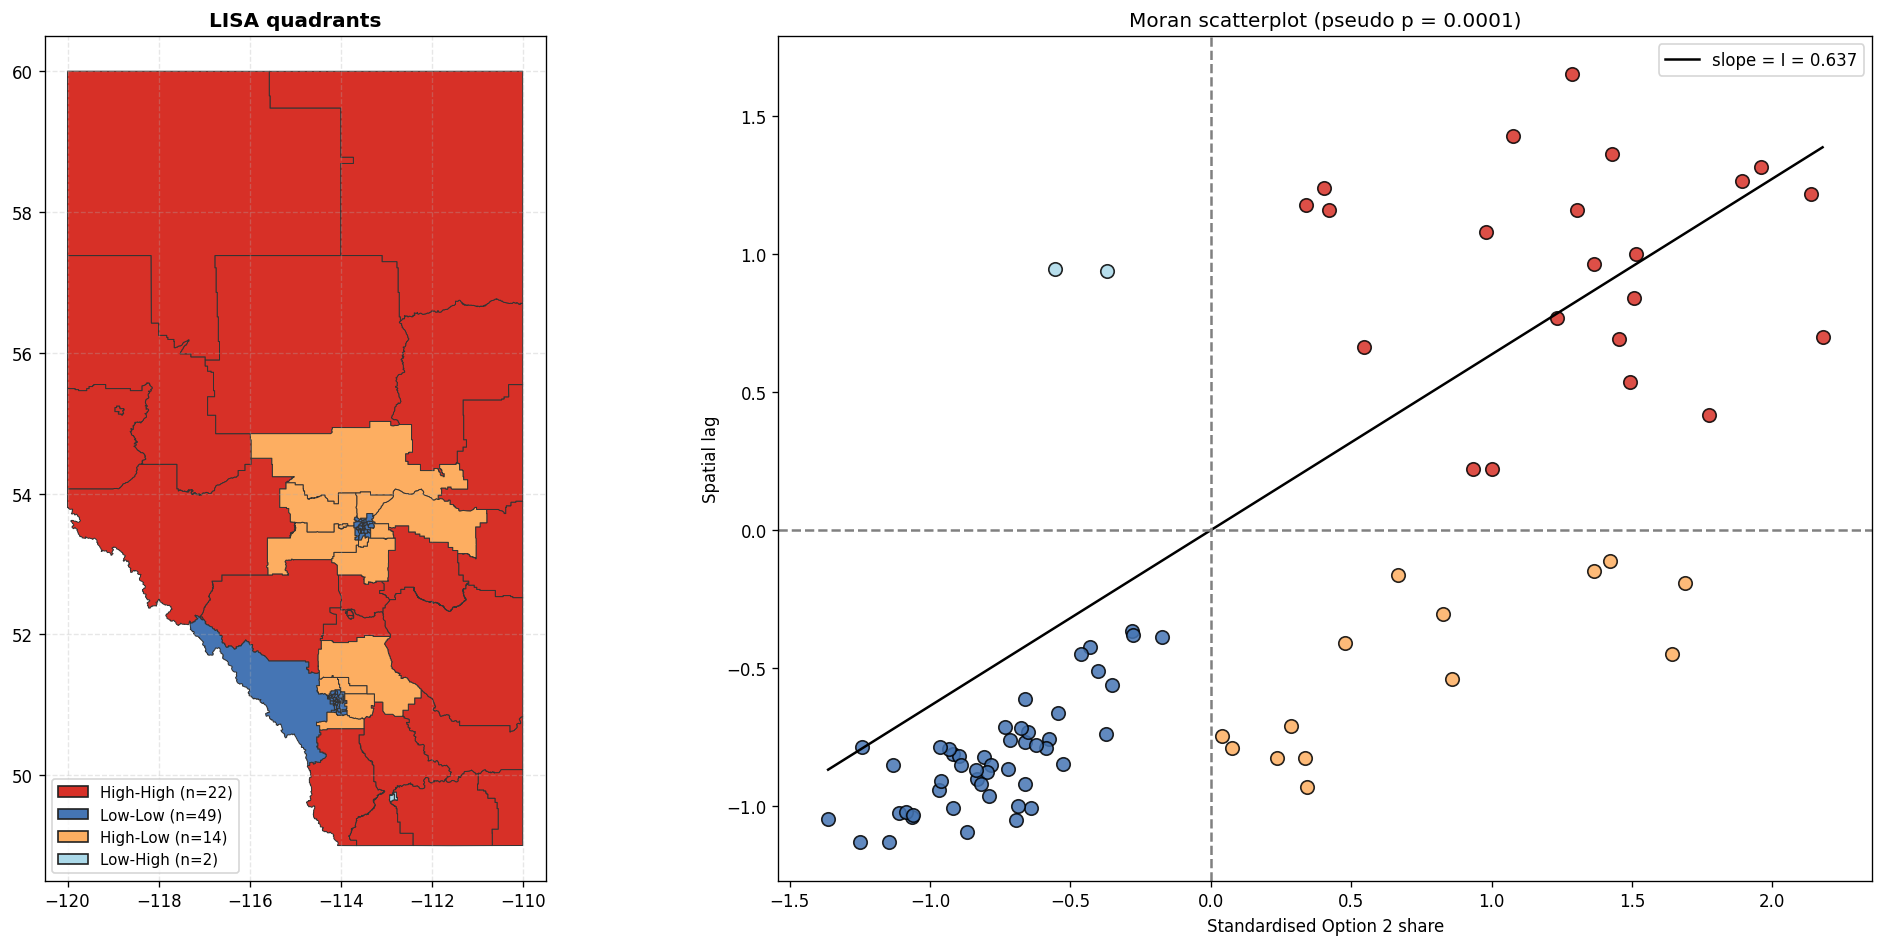

lisa
Low-Low      49
High-High    22
High-Low     14
Low-High      2
Name: count, dtype: int64

In [5]:
z = (y - y.mean()) / y.std()
lag = W @ z
df["z"], df["lag"] = z, lag
df["lisa"] = np.select(
    [(z > 0) & (lag > 0), (z < 0) & (lag < 0), (z > 0) & (lag < 0)],
    ["High-High", "Low-Low", "High-Low"], default="Low-High")

fig, (ax_map, ax_sc) = plt.subplots(1, 2, figsize=(18, 8), dpi=120)
gdf["lisa"] = df["lisa"].to_numpy()
patches = []
for name, colour in LISA_COLOURS.items():
    sub = gdf[gdf["lisa"] == name]
    if len(sub):
        sub.plot(color=colour, edgecolor="#333333", linewidth=0.6, ax=ax_map)
    ax_sc.scatter(df.loc[df["lisa"] == name, "z"], df.loc[df["lisa"] == name, "lag"], c=colour, s=65, edgecolor="black", alpha=0.85)
    patches.append(mpatches.Patch(facecolor=colour, edgecolor="#222222", label=f"{name} (n={len(sub)})"))
ax_map.legend(handles=patches, loc="lower left", fontsize=9)
ax_map.set_title("LISA quadrants", fontsize=12, fontweight="bold")
ax_map.set_xlim(-120.5, -109.5); ax_map.set_ylim(48.5, 60.5)
ax_map.grid(True, linestyle="--", alpha=0.3)
xs = np.linspace(z.min(), z.max(), 20)
ax_sc.plot(xs, i_obs * xs, color="black", label=f"slope = I = {i_obs:.3f}")
ax_sc.axhline(0, color="grey", linestyle="--"); ax_sc.axvline(0, color="grey", linestyle="--")
ax_sc.set_xlabel("Standardised Option 2 share"); ax_sc.set_ylabel("Spatial lag")
ax_sc.set_title(f"Moran scatterplot (pseudo p = {p_value:.4f})")
ax_sc.legend()
plt.tight_layout(); plt.show()
df["lisa"].value_counts()

## 5. Rankings and regional comparison

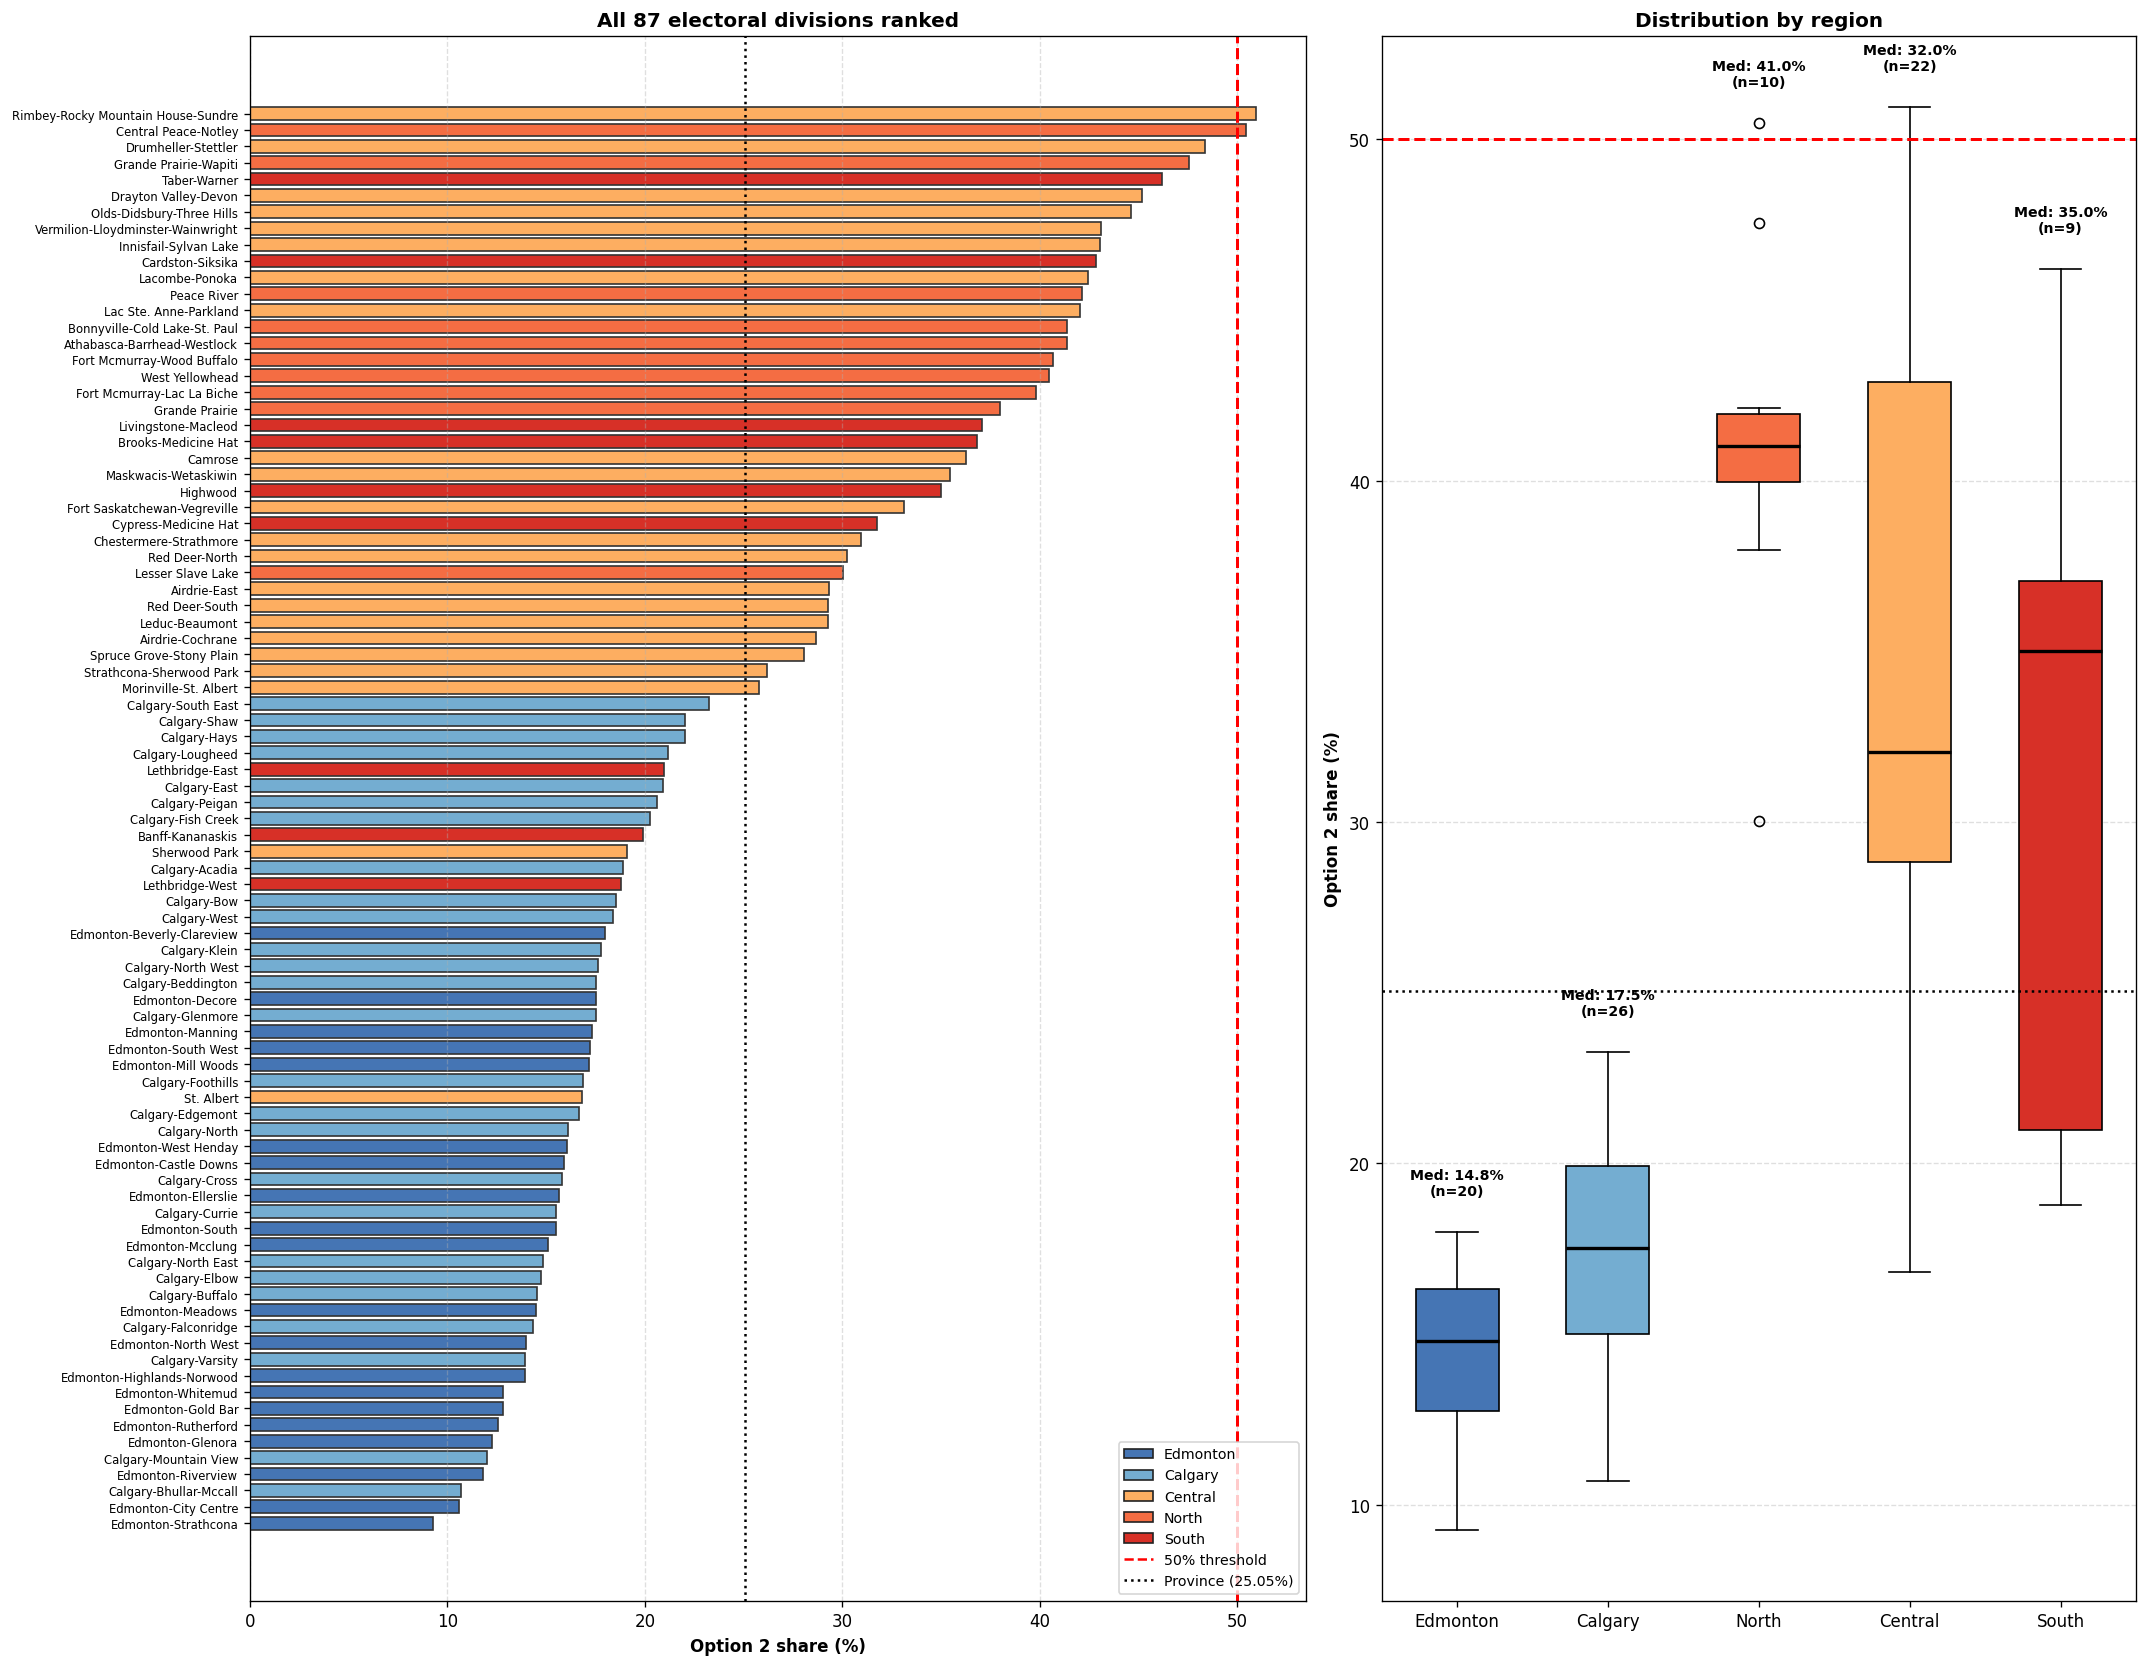

,n,median,mean,min,max
region,,,,,
Calgary,26,17.51,17.41,10.68,23.27
Central,22,32.04,34.47,16.81,50.94
Edmonton,20,14.80,14.50,9.28,17.99
North,10,41.01,41.18,30.04,50.46
South,9,35.02,32.15,18.78,46.20


In [6]:
prov = 100 * df["choice_2_votes"].sum() / df["total"].sum()
order = ["Edmonton", "Calgary", "North", "Central", "South"]
ranked = df.sort_values("option2_pct")

fig, (ax_bar, ax_box) = plt.subplots(1, 2, figsize=(18, 14), dpi=120, gridspec_kw={"width_ratios": [1.4, 1.0]})
ax_bar.barh(np.arange(len(ranked)), ranked["option2_pct"], color=[REGION_COLOURS[r] for r in ranked["region"]],
            edgecolor="#333333", height=0.78)
ax_bar.axvline(50, color="red", linestyle="--", linewidth=1.8)
ax_bar.axvline(prov, color="black", linestyle=":", linewidth=1.5)
ax_bar.set_yticks(np.arange(len(ranked))); ax_bar.set_yticklabels(ranked["ed_name"].str.title(), fontsize=7)
ax_bar.set_xlabel("Option 2 share (%)", fontweight="bold")
ax_bar.set_title("All 87 electoral divisions ranked", fontsize=12, fontweight="bold")
handles = [mpatches.Patch(facecolor=c_, edgecolor="#222222", label=r) for r, c_ in REGION_COLOURS.items()]
handles += [plt.Line2D([0], [0], color="red", linestyle="--", label="50% threshold"),
            plt.Line2D([0], [0], color="black", linestyle=":", label=f"Province ({prov:.2f}%)")]
ax_bar.legend(handles=handles, loc="lower right", fontsize=8.5)
ax_bar.grid(True, axis="x", linestyle="--", alpha=0.4)

bp = ax_box.boxplot([df.loc[df["region"] == r, "option2_pct"] for r in order], tick_labels=order, patch_artist=True, widths=0.55)
for patch, r in zip(bp["boxes"], order):
    patch.set_facecolor(REGION_COLOURS[r])
for med in bp["medians"]:
    med.set(color="black", linewidth=2)
ax_box.axhline(50, color="red", linestyle="--", linewidth=1.8)
ax_box.axhline(prov, color="black", linestyle=":", linewidth=1.5)
for i, r in enumerate(order, start=1):
    sub = df.loc[df["region"] == r, "option2_pct"]
    ax_box.text(i, sub.max() + 1.0, f"Med: {sub.median():.1f}%\n(n={len(sub)})", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax_box.set_ylabel("Option 2 share (%)", fontweight="bold")
ax_box.set_title("Distribution by region", fontsize=12, fontweight="bold")
ax_box.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

display(df.groupby("region")["option2_pct"].agg(n="count", median="median", mean="mean", min="min", max="max").round(2))

## Next steps
- Verify the region labels in `ed_regions.csv` against an independent source.
- Add a local significance test for LISA.
- Add real covariates (for example Statistics Canada indicators, 2023 election results) before any spatial lag model.